# Tech Challenge — Fase 4 | Olist: Voz do Cliente com RAG

**Projeto de NLP e RAG

A proposta é responder perguntas sobre o que os clientes falam nas avaliações da Olist. Minha solução primeiro encontra avaliações parecidas com a pergunta e depois entrega esses comentários como contexto para um modelo de linguagem.

Eu separei o trabalho em **preparação das tabelas**, **análise dos textos**, **busca por similaridade** e **resposta com fontes**. Os cruzamentos foram feitos com `pandas.merge()`, para ficar claro de onde veio cada informação. Não vou treinar uma rede neural do zero.

> A geração final depende de um Ollama instalado no computador. Entretanto, este notebook também executa sem Ollama e mostra as fontes recuperadas.

## 1. Importações e caminhos

O arquivo ZIP original fica em `data/raw/`. Todos os caminhos são relativos à pasta do projeto, então não precisam ser alterados no computador de outra pessoa.

In [11]:
from pathlib import Path
import sys
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

RAIZ = Path.cwd()
if RAIZ.name == 'notebooks':
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

ORIGEM = RAIZ / 'data' / 'raw'
DESTINO = RAIZ / 'data' / 'processed'
ZIP = ORIGEM / 'olist_dataset_original.zip'
DESTINO.mkdir(parents=True, exist_ok=True)
assert ZIP.exists(), 'Coloque o ZIP em data/raw/olist_dataset_original.zip'
print('Pasta do projeto:', RAIZ)

Pasta do projeto: c:\Users\Gui\OneDrive\Documentos\FIAP_AULAS\FASE4


## 2. Leitura das bases originais

Descompactei somente as **sete tabelas usadas** na análise. Depois li cada CSV com `pd.read_csv()`. A Olist também tem geolocalização e vendedores, mas não precisamos dessas duas tabelas para investigar o conteúdo das avaliações.

A primeira verificação é conferir a quantidade de registros e a chave principal de cada base.

In [12]:
nomes_arquivos = [
    'olist_order_reviews_dataset.csv',
    'olist_orders_dataset.csv',
    'olist_customers_dataset.csv',
    'olist_order_items_dataset.csv',
    'olist_products_dataset.csv',
    'product_category_name_translation.csv',
    'olist_order_payments_dataset.csv'
]

with zipfile.ZipFile(ZIP) as arquivo_zip:
    for nome in nomes_arquivos:
        if not (ORIGEM / nome).exists():
            arquivo_zip.extract(nome, ORIGEM)

avaliacoes = pd.read_csv(ORIGEM / 'olist_order_reviews_dataset.csv')
pedidos = pd.read_csv(ORIGEM / 'olist_orders_dataset.csv')
clientes = pd.read_csv(ORIGEM / 'olist_customers_dataset.csv')
itens = pd.read_csv(ORIGEM / 'olist_order_items_dataset.csv')
produtos = pd.read_csv(ORIGEM / 'olist_products_dataset.csv')
categorias = pd.read_csv(ORIGEM / 'product_category_name_translation.csv')
pagamentos = pd.read_csv(ORIGEM / 'olist_order_payments_dataset.csv')

quantidades = pd.DataFrame({
    'base': ['avaliações', 'pedidos', 'clientes', 'itens', 'produtos', 'categorias', 'pagamentos'],
    'linhas': [len(avaliacoes), len(pedidos), len(clientes), len(itens),
               len(produtos), len(categorias), len(pagamentos)]
})
display(quantidades)

,base,linhas
0,avaliações,99224
1,pedidos,99441
2,clientes,99441
3,itens,112650
4,produtos,32951
5,categorias,71
6,pagamentos,103886


## 3. Como as tabelas se relacionam

O ponto de partida é a avaliação, identificada por `review_id`, e o **pedido** é a ligação principal.

```text
avaliações ── order_id ──► pedidos ── customer_id ──► clientes
                              │
                              ├── order_id ──► itens ── product_id ──► produtos ──► categorias
                              │
                              └── order_id ──► pagamentos
```

| Tabelas | Chave | Relacionamento | Cuidado |
|---|---|---|---|
| Pedidos → clientes | `customer_id` | Muitos pedidos? Na Olist, um registro de cliente por pedido | `many_to_one` |
| Itens → produtos | `product_id` | Vários itens podem usar o mesmo produto | `many_to_one` |
| Produtos → categorias | `product_category_name` | Muitas referências à mesma categoria | `many_to_one` |
| Pedidos → itens | `order_id` | Um pedido pode ter vários itens | **Agrupar antes do merge** |
| Pedidos → pagamentos | `order_id` | Um pedido pode ter vários pagamentos | **Agrupar antes do merge** |
| Avaliações → pedidos | `order_id` | Cada avaliação pertence a um pedido | `many_to_one` |

Por que agrupar antes? Se um pedido tem **2 itens e 2 pagamentos**, um `merge()` direto criaria **4 linhas** para o mesmo pedido. Para evitar esse erro, deixei uma linha por pedido em `itens_por_pedido` e `pagamentos_por_pedido`.

## 4. Limpeza dos comentários

Como o objetivo é estudar textos, avaliações sem título **e** sem comentário são removidas. Eu mantive a nota e as chaves para conseguir localizar cada avaliação na base de origem.

Não removi pontuação nem palavras comuns: elas podem ajudar a interpretar o sentido dos comentários.

In [13]:
avaliacoes['titulo'] = avaliacoes['review_comment_title'].fillna('').astype(str).str.strip()
avaliacoes['comentario'] = avaliacoes['review_comment_message'].fillna('').astype(str).str.strip()

avaliacoes['titulo'] = avaliacoes['titulo'].str.replace(r'\s+', ' ', regex=True)
avaliacoes['comentario'] = avaliacoes['comentario'].str.replace(r'\s+', ' ', regex=True)
avaliacoes['texto'] = (avaliacoes['titulo'] + '. ' + avaliacoes['comentario']).str.strip(' .')

avaliacoes_texto = avaliacoes[avaliacoes['texto'].str.len() >= 3].copy()
avaliacoes_texto = avaliacoes_texto.drop_duplicates(subset=['review_id', 'order_id'])

print('Avaliações originais:', len(avaliacoes))
print('Avaliações que possuem texto, sem duplicidades:', len(avaliacoes_texto))
display(avaliacoes_texto[['review_id', 'order_id', 'review_score', 'texto']].head(3))

Avaliações originais: 99224
Avaliações que possuem texto, sem duplicidades: 42343


,review_id,order_id,review_score,texto
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,Recebi bem antes do prazo estipulado
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,Parabéns lojas lannister adorei comprar pela I...
9,8670d52e15e00043ae7de4c01cc2fe06,b9bf720beb4ab3728760088589c62129,4,recomendo. aparelho eficiente. no site a marca...


## 5. Cruzamento dos itens com produtos e categorias

Cada item tem um `product_id`. Uso essa coluna para trazer sua categoria e depois traduzi-la para inglês, pois a tabela auxiliar já oferece essa descrição.

**Aqui ainda há mais de uma linha por pedido:** é o esperado para uma tabela de itens.

In [14]:
itens_produtos = itens.merge(
    produtos[['product_id', 'product_category_name']],
    on='product_id', how='left', validate='many_to_one'
)

itens_produtos = itens_produtos.merge(
    categorias,
    on='product_category_name', how='left', validate='many_to_one'
)

itens_produtos['categoria'] = (
    itens_produtos['product_category_name_english']
    .fillna(itens_produtos['product_category_name'])
    .fillna('não informada')
)

assert len(itens_produtos) == len(itens), 'O merge dos produtos multiplicou linhas!'
print('Itens antes e depois das junções:', len(itens), '→', len(itens_produtos))
display(itens_produtos[['order_id', 'product_id', 'categoria', 'price']].head(3))

Itens antes e depois das junções: 112650 → 112650


,order_id,product_id,categoria,price
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,cool_stuff,58.9
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,pet_shop,239.9
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,furniture_decor,199.0


## 6. Resumo dos itens e dos pagamentos por pedido

A partir daqui o objetivo é ter **uma linha por `order_id`**. Uso `groupby()` para somar valores e contar itens.

Para não perder pedidos com categorias diferentes, guardo os nomes das categorias separados por `|` — é a única agregação de texto deste passo.

In [15]:
itens_por_pedido = itens_produtos.groupby('order_id', as_index=False).agg(
    qtd_itens=('order_item_id', 'count'),
    valor_produtos=('price', 'sum'),
    valor_frete=('freight_value', 'sum')
)

categorias_por_pedido = (itens_produtos.groupby('order_id')['categoria']
    .apply(lambda serie: ' | '.join(sorted(serie.dropna().unique())))
    .reset_index(name='categorias'))

itens_por_pedido = itens_por_pedido.merge(
    categorias_por_pedido, on='order_id', how='left', validate='one_to_one'
)

pagamentos_por_pedido = (pagamentos.groupby('order_id', as_index=False)
    .agg(valor_pago=('payment_value', 'sum')))

assert itens_por_pedido['order_id'].is_unique
assert pagamentos_por_pedido['order_id'].is_unique
print('Pedidos com itens:', len(itens_por_pedido))
print('Pedidos com pagamentos:', len(pagamentos_por_pedido))
display(itens_por_pedido.head(3))

Pedidos com itens: 98666
Pedidos com pagamentos: 99440


,order_id,qtd_itens,valor_produtos,valor_frete,categorias
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.9,13.29,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,239.9,19.93,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,199.0,17.87,furniture_decor


## 7. Cruzamento de pedidos com clientes, itens e pagamentos

O pedido é a nossa tabela central. Cada `merge()` adiciona um assunto:

1. **Clientes:** cidade e estado.
2. **Itens resumidos:** quantidade, preço, frete e categorias.
3. **Pagamentos resumidos:** valor total pago.

O `validate` verifica a cardinalidade de cada relacionamento.

In [16]:
pedidos_completos = pedidos.merge(
    clientes[['customer_id', 'customer_city', 'customer_state']],
    on='customer_id', how='left', validate='many_to_one'
)
print('Após juntar clientes:', len(pedidos_completos))

pedidos_completos = pedidos_completos.merge(
    itens_por_pedido, on='order_id', how='left', validate='one_to_one'
)
print('Após juntar itens:', len(pedidos_completos))

pedidos_completos = pedidos_completos.merge(
    pagamentos_por_pedido, on='order_id', how='left', validate='one_to_one'
)
print('Após juntar pagamentos:', len(pedidos_completos))

assert len(pedidos_completos) == len(pedidos)
assert pedidos_completos['order_id'].is_unique

Após juntar clientes: 99441
Após juntar itens: 99441
Após juntar pagamentos: 99441


## 8. Datas de entrega e base final de avaliações

Converto duas datas para calcular o atraso: `dias_atraso > 0` indica entrega posterior à data estimada. Quando não existe entrega, esse campo fica vazio; não suponho que o pedido atrasou.

Por fim, junto **avaliações com texto** aos **pedidos completos** usando `order_id`. Esta é a tabela que alimenta a busca do RAG.

In [17]:
pedidos_completos['order_purchase_timestamp'] = pd.to_datetime(
    pedidos_completos['order_purchase_timestamp'], errors='coerce')
pedidos_completos['order_delivered_customer_date'] = pd.to_datetime(
    pedidos_completos['order_delivered_customer_date'], errors='coerce')
pedidos_completos['order_estimated_delivery_date'] = pd.to_datetime(
    pedidos_completos['order_estimated_delivery_date'], errors='coerce')

pedidos_completos['dias_atraso'] = (
    pedidos_completos['order_delivered_customer_date'] -
    pedidos_completos['order_estimated_delivery_date']
).dt.days

colunas_pedido = [
    'order_id', 'order_status', 'order_purchase_timestamp',
    'customer_city', 'customer_state', 'qtd_itens',
    'valor_produtos', 'valor_frete', 'valor_pago', 'categorias', 'dias_atraso'
]

documentos = avaliacoes_texto.merge(
    pedidos_completos[colunas_pedido],
    on='order_id', how='left', validate='many_to_one'
)

documentos['ano_compra'] = documentos['order_purchase_timestamp'].dt.year
documentos['categorias'] = documentos['categorias'].fillna('não informada')
documentos['id_documento'] = documentos['review_id'] + '|' + documentos['order_id']

colunas_finais = [
    'id_documento', 'review_id', 'order_id', 'review_score', 'texto',
    'review_creation_date', 'ano_compra', 'categorias', 'order_status',
    'dias_atraso', 'customer_city', 'customer_state', 'qtd_itens',
    'valor_produtos', 'valor_frete', 'valor_pago'
]
documentos = documentos[colunas_finais].reset_index(drop=True)

assert len(documentos) == len(avaliacoes_texto)
assert documentos['id_documento'].is_unique
assert documentos['texto'].str.len().ge(3).all()

print('Avaliações com texto:', len(avaliacoes_texto))
print('Avaliações após o merge:', len(documentos))
display(documentos[['review_score', 'texto', 'categorias', 'dias_atraso']].head(4))

Avaliações com texto: 42343
Avaliações após o merge: 42343


,review_score,texto,categorias,dias_atraso
0,5,Recebi bem antes do prazo estipulado,garden_tools,-20.0
1,5,Parabéns lojas lannister adorei comprar pela I...,sports_leisure,-9.0
2,4,recomendo. aparelho eficiente. no site a marca...,small_appliances,-16.0
3,4,"Mas um pouco ,travando...pelo valor ta Boa",health_beauty,-11.0


## 9. Salvando as bases tratadas

Salvo três tabelas em CSV compactado (`.csv.gz`), que o Pandas lê normalmente com `pd.read_csv()`. A partir delas podemos refazer análises sem repetir todas as junções.

- `itens_enriquecidos`: item + produto + categoria.
- `pedidos_relacionados`: pedido + cliente + resumo de itens e pagamentos.
- `avaliacoes_tratadas`: um documento por avaliação com texto, com os metadados para o RAG.

In [18]:
itens_produtos.to_csv(DESTINO / 'itens_enriquecidos.csv.gz', index=False)
pedidos_completos.to_csv(DESTINO / 'pedidos_relacionados.csv.gz', index=False)
documentos.to_csv(DESTINO / 'avaliacoes_tratadas.csv.gz', index=False)

validacao = pd.DataFrame([
    ['Avaliações na origem', len(avaliacoes)],
    ['Avaliações com texto', len(avaliacoes_texto)],
    ['Pedidos na origem', len(pedidos)],
    ['Pedidos após os merges', len(pedidos_completos)],
    ['Documentos para o RAG', len(documentos)]
], columns=['Etapa', 'Linhas'])
display(validacao)
assert len(pd.read_csv(DESTINO / 'avaliacoes_tratadas.csv.gz')) == len(documentos)

,Etapa,Linhas
0,Avaliações na origem,99224
1,Avaliações com texto,42343
2,Pedidos na origem,99441
3,Pedidos após os merges,99441
4,Documentos para o RAG,42343


## 10. Entendendo as avaliações com uma análise simples

Antes de usar NLP, verifiquei a distribuição das notas. Isso ajuda a explicar por que um comentário positivo não deve ser tratado como reclamação apenas por citar a palavra "entrega".

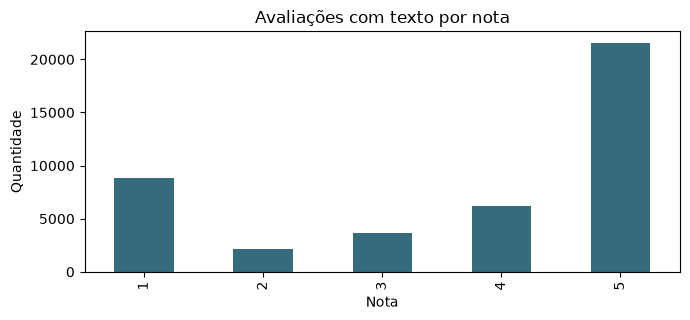

Avaliações nota 1 ou 2: 10971


In [19]:
distribuicao_notas = documentos['review_score'].value_counts().sort_index()
ax = distribuicao_notas.plot(kind='bar', figsize=(7, 3.3), color='#356b7b')
ax.set(title='Avaliações com texto por nota', xlabel='Nota', ylabel='Quantidade')
plt.tight_layout()
(RAIZ / 'images').mkdir(exist_ok=True)
plt.savefig(RAIZ / 'images' / 'notas_avaliacoes.png', dpi=150)
plt.show()
print('Avaliações nota 1 ou 2:', int(documentos['review_score'].le(2).sum()))

## 11. Representação dos textos: TF-IDF e embeddings

**Primeira tentativa — TF-IDF:** dá mais peso às palavras importantes do comentário. É simples e útil para comparar resultados.

**Segunda tentativa — LSA:** pega a matriz TF-IDF e usa `TruncatedSVD` para gerar vetores menores e densos (*embeddings*). Essa redução tenta capturar relações entre palavras e documentos, mas também pode perder detalhes.

Usei o scikit-learn nas duas etapas, sem treinar redes neurais. Mais abaixo deixei uma opção com um **modelo de NLP pré-treinado (MiniLM)** caso eu queira melhorar a busca sem precisar criar um modelo próprio.

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

vetorizador = TfidfVectorizer(
    strip_accents='unicode', max_features=12000, min_df=2,
    ngram_range=(1, 2)
)
matriz_tfidf = vetorizador.fit_transform(documentos['texto'])

redutor = TruncatedSVD(n_components=64, n_iter=3, random_state=42)
embeddings_lsa = normalize(redutor.fit_transform(matriz_tfidf)).astype('float32')

indice_tfidf = {
    'metodo': 'tfidf', 'dados': documentos,
    'tfidf': vetorizador, 'vetores': matriz_tfidf
}
indice_lsa = {
    'metodo': 'lsa', 'dados': documentos,
    'tfidf': vetorizador, 'lsa': redutor, 'vetores': embeddings_lsa
}

print('TF-IDF (documentos x termos):', matriz_tfidf.shape)
print('Embeddings LSA (documentos x dimensões):', embeddings_lsa.shape)
np.save(RAIZ / 'artifacts' / 'embeddings_lsa.npy', embeddings_lsa)

#apenas teste

TF-IDF (documentos x termos): (42343, 12000)
Embeddings LSA (documentos x dimensões): (42343, 64)


## 12. Comparação das duas formas de busca

Testei as duas buscas com as **mesmas perguntas** e os **mesmos documentos**. A contagem abaixo é uma verificação rápida: quantos comentários retornados têm expressões relacionadas ao assunto? Não é uma nota de precisão calculada por avaliadores humanos.

Essa comparação mostra como uma mudança de representação pode alterar os textos encontrados. Não vou afirmar que LSA ou MiniLM sempre serão melhores; o resultado depende da pergunta.

In [23]:
from src.rag_simples import buscar, responder, criar_contexto

perguntas_teste = [
    ('atraso', 'Quais reclamações existem sobre atraso na entrega?', ['atras', 'demor', 'prazo']),
    ('quebrado', 'Os clientes reclamam de produtos quebrados?', ['quebrad', 'danific', 'avari']),
    ('embalagem', 'Há reclamações sobre embalagens dos produtos?', ['embalag', 'caixa', 'empacot']),
]

linhas_comparacao = []
for tema, pergunta, palavras in perguntas_teste:
    for nome, indice_temp in [('TF-IDF', indice_tfidf), ('LSA', indice_lsa)]:
        encontrados = buscar(pergunta, indice_temp, k=5, nota_max=2)
        com_termo = sum(any(p in e['texto'].lower() for p in palavras)
                        for e in encontrados)
        linhas_comparacao.append({
            'tema': tema, 'busca': nome, 'comentarios': len(encontrados),
            'com_termos_do_tema': com_termo
        })
comparacao = pd.DataFrame(linhas_comparacao)
display(comparacao)
(RAIZ / 'results').mkdir(exist_ok=True)
comparacao.to_csv(RAIZ / 'results' / 'comparacao_buscas.csv', index=False)

print('Exemplo de comentários para a pergunta sobre produtos quebrados:')
for titulo, indice_temp in [('TF-IDF', indice_tfidf), ('LSA', indice_lsa)]:
    print('\n' + titulo)
    for item in buscar('Os clientes reclamam de produtos quebrados?', indice_temp, k=2, nota_max=2):
        print('-', item['texto'][:180])

,tema,busca,comentarios,com_termos_do_tema
0,atraso,TF-IDF,5,5
1,atraso,LSA,5,5
2,quebrado,TF-IDF,5,1
3,quebrado,LSA,5,0
4,embalagem,TF-IDF,5,1
5,embalagem,LSA,5,0


Exemplo de comentários para a pergunta sobre produtos quebrados:

TF-IDF
- tablets quebrados. alguns tablets de bcaa vieram quebrados, diminuindo a qualidade do produto
- Anúncio e venda de produtos indisponíveis

LSA
- muitos desencontros nas entregas de produtos
- Anúncio e venda de produtos indisponíveis


## 13. Modelo de NLP já pronto (opcional): MiniLM

Para quem quiser usar embeddings gerados por uma rede neural pré-treinada, basta instalar `requirements-minilm.txt` e mudar a variável `USAR_MINILM` para `True`, caso contrário deixe em `False`.

O modelo é o `paraphrase-multilingual-MiniLM-L12-v2`, treinado previamente para representar frases de vários idiomas. **Não é necessário treiná-lo com as avaliações**. A primeira execução faz download do modelo e a vetorização de todas as avaliações pode levar algum tempo em computadores sem GPU.

O notebook continua executável sem esse download, usando **TF-IDF** como busca padrão, conforme a comparação real acima. Os embeddings LSA foram calculados para estudar a diferença entre as representações. Não comparo um resultado MiniLM que eu não tenha executado.

In [25]:
USAR_MINILM = True  # Trocar para True somente após instalar sentence-transformers

# Na comparação de 3 perguntas, o TF-IDF encontrou mais termos relevantes.
# Por isso usei TF-IDF como padrão e deixei o MiniLM como evolução opcional.
indice_rag = indice_tfidf
if USAR_MINILM:
    from sentence_transformers import SentenceTransformer
    modelo_minilm = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
    cache_minilm = RAIZ / 'artifacts' / 'embeddings_minilm.npy'

    if cache_minilm.exists():
        embeddings_minilm = np.load(cache_minilm)
        assert len(embeddings_minilm) == len(documentos), 'Exclua o cache: base mudou'
    else:
        embeddings_minilm = modelo_minilm.encode(
            documentos['texto'].tolist(), batch_size=64,
            show_progress_bar=True, normalize_embeddings=True
        )
        np.save(cache_minilm, embeddings_minilm)

    indice_rag = {
        'metodo': 'minilm', 'dados': documentos,
        'modelo': modelo_minilm, 'vetores': embeddings_minilm
    }

print('Método escolhido para o RAG:', indice_rag['metodo'])

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

c:\Users\Gui\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Gui\.cache\huggingface\hub\models--sentence-transformers--paraphrase-multilingual-MiniLM-L12-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/662 [00:00<?, ?it/s]

Método escolhido para o RAG: minilm


In [ ]:
USAR_MINILM = False  # Trocar para True somente após instalar sentence-transformers

# Na comparação de 3 perguntas, o TF-IDF encontrou mais termos relevantes.
# Por isso usei TF-IDF como padrão e deixei o MiniLM como evolução opcional.
indice_rag = indice_tfidf
if USAR_MINILM:
    from sentence_transformers import SentenceTransformer
    modelo_minilm = SentenceTransformer('sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2')
    cache_minilm = RAIZ / 'artifacts' / 'embeddings_minilm.npy'

    if cache_minilm.exists():
        embeddings_minilm = np.load(cache_minilm)
        assert len(embeddings_minilm) == len(documentos), 'Exclua o cache: base mudou'
    else:
        embeddings_minilm = modelo_minilm.encode(
            documentos['texto'].tolist(), batch_size=64,
            show_progress_bar=True, normalize_embeddings=True
        )
        np.save(cache_minilm, embeddings_minilm)

    indice_rag = {
        'metodo': 'minilm', 'dados': documentos,
        'modelo': modelo_minilm, 'vetores': embeddings_minilm
    }

print('Método escolhido para o RAG:', indice_rag['metodo'])

## 14. Como acontece o RAG

O fluxo é:

**Pergunta → vetor da pergunta → avaliações parecidas → contexto com IDs → LLM → resposta citando os IDs.**

As avaliações escolhidas recebem identificadores `[E1]`, `[E2]` etc. Em cada uma mostro o `review_id`, a nota e o texto original. Assim conseguimos conferir se uma conclusão realmente aparece nos dados.

**Ajuste que fiz na pergunta:** uma consulta genérica sobre “problemas dos clientes” também traz textos de produtos e atendimento. Ao perguntar especificamente sobre **entrega atrasada**, os primeiros resultados passam a falar diretamente de atraso. Isso é uma observação da busca, não um treinamento novo.

In [ ]:
pergunta = 'O que os clientes relatam sobre entrega atrasada?'
evidencias = buscar(pergunta, indice_rag, k=5, nota_max=2)
print('Pergunta:', pergunta)
display(pd.DataFrame(evidencias)[['fonte', 'review_id', 'nota', 'similaridade', 'texto']])
print('\nContexto enviado ao LLM:\n')
print(criar_contexto(evidencias)[:1600])
assert len(evidencias) >= 2, 'Não foram encontradas avaliações suficientes neste exemplo'

Pergunta: O que os clientes relatam sobre entrega atrasada?


,fonte,review_id,nota,similaridade,texto
0,E1,7c0de218885cc260013e84382ecff66c,1,0.572,Entrega atrasada!
1,E2,e74598307b6209e21d6514a830224b76,1,0.572,Entrega atrasada
2,E3,db64106aff6c7180cb841937f43f5f44,1,0.453,Entrega atrasada. Ainda não recebi o produto
3,E4,8f9772ae7dec3db4af0418fd7fb1be4d,1,0.448,Produto com entrega atrasada
4,E5,1bfec3e913196c72c1ea06fc8816bd9c,1,0.427,entrega atrasada. o prazo terminou e nao receb...



Contexto enviado ao LLM:

[E1] Nota 1/5, review_id=7c0de218885cc260013e84382ecff66c: Entrega atrasada!
[E2] Nota 1/5, review_id=e74598307b6209e21d6514a830224b76: Entrega atrasada
[E3] Nota 1/5, review_id=db64106aff6c7180cb841937f43f5f44: Entrega atrasada. Ainda não recebi o produto
[E4] Nota 1/5, review_id=8f9772ae7dec3db4af0418fd7fb1be4d: Produto com entrega atrasada
[E5] Nota 1/5, review_id=1bfec3e913196c72c1ea06fc8816bd9c: entrega atrasada. o prazo terminou e nao recebi meu produto


## 15. Resposta final e integração com o Ollama

O código já contém uma integração com um LLM local (Ollama, modelo `llama3.2:3b`). Com `USAR_OLLAMA=True`, o modelo recebe somente os comentários recuperados e deve citar as fontes.

**Nesta execução deixei `False`:** como não há Ollama aqui, seria incorreto mostrar um texto inventado como se o modelo tivesse respondido. No modo desligado aparecem diretamente as avaliações. No README estão os comandos para habilitar a geração em outro computador.

In [ ]:
USAR_OLLAMA = False  # Para gerar texto, instalar Ollama e baixar llama3.2:3b
resultado = responder(
    pergunta, indice_rag, usar_ollama=USAR_OLLAMA, nota_max=2
)
print('Modo:', resultado['modo'])
print(resultado['resposta'])

Modo: consulta de evidências
Avaliações encontradas (sem gerar resposta com LLM):
[E1] Entrega atrasada! (nota 1/5)
[E2] Entrega atrasada (nota 1/5)
[E3] Entrega atrasada. Ainda não recebi o produto (nota 1/5)
[E4] Produto com entrega atrasada (nota 1/5)
[E5] entrega atrasada. o prazo terminou e nao recebi meu produto (nota 1/5)


In [26]:
USAR_OLLAMA = True  # Para gerar texto, instalar Ollama e baixar llama3.2:3b
resultado = responder(
    pergunta, indice_rag, usar_ollama=USAR_OLLAMA, nota_max=2
)
print('Modo:', resultado['modo'])
print(resultado['resposta'])

Modo: RAG com Ollama
Sim, há reclamações sobre embalagens dos produtos. As avaliações [E1], [E5] e [E4] mencionam problemas com a embalagem, como riscos, amassados, manchas de utilização e avarias na pintura. Além disso, a avaliação [E5] também sugere que a embalagem não é adequada para produtos frágeis, como a menção à necessidade de avisos de "Frágil" ou não pisar.

Fontes: [E1], [E4], [E5]


## 16. Situações em que não devemos responder

Também testei a limitação da base: perguntas fora do tema, ano sem registros e categoria inexistente. É melhor dizer que não temos dados suficientes do que inventar uma conclusão.

In [ ]:
testes = [
    ('Qual a previsão do tempo para amanhã?', {}),
    ('Quais reclamações sobre entrega ocorreram em 2035?', {'ano': 2035}),
    ('Quais são os elogios para a categoria foguete_espacial?', {'categoria': 'foguete_espacial'})
]

for pergunta_teste, filtros in testes:
    saida = responder(pergunta_teste, indice_rag, **filtros)
    print('Pergunta:', pergunta_teste)
    print('Resultado:', saida['resposta'], '\n')
    assert saida['modo'] == 'sem evidências'

Pergunta: Qual a previsão do tempo para amanhã?
Resultado: Não encontrei avaliações suficientes para responder. 

Pergunta: Quais reclamações sobre entrega ocorreram em 2035?
Resultado: Não encontrei avaliações suficientes para responder. 



Pergunta: Quais são os elogios para a categoria foguete_espacial?
Resultado: Não encontrei avaliações suficientes para responder. 



## 17. Conclusões e limites

- Consegui ler as bases, limpar os comentários e cruzar os dados **sem multiplicar indevidamente os pedidos**.
- O projeto trabalha com avaliações reais e permite buscar documentos por assunto, nota, ano e categoria.
- Comparei TF-IDF com LSA de forma simples. **Neste teste, o TF-IDF encontrou termos mais alinhados nas perguntas sobre produtos quebrados e embalagens; por isso ficou como padrão.** A métrica baseada em palavras não equivale a uma avaliação humana de relevância.
- Os embeddings LSA foram criados e testados, mas não renderam melhor nesse conjunto pequeno. O modelo MiniLM é outra possibilidade usando NLP pré-treinado; ele é **opcional** e precisa ser executado para ter resultados medidos.
- Os comentários foram escritos principalmente entre 2016 e 2018; eles não representam clientes atuais e podem conter erros, ironias ou relatos contraditórios.

O mais importante no desafio é que o sistema não responde sem base: cada evidência mantém a nota, o comentário, o pedido e a avaliação de origem.